# 02 — Classification: full reproducible evaluation

**Owner:** Germain. **Feature pipeline:** Joseph (`src/features.py`). **Cost assumptions:** Liza (`learnings/04_cost_matrix.md`).

Run from a fresh clone after installing `requirements.txt` and downloading the Zindi dataset into `data/zindi/`. This notebook does not need prior `data/experiments` CSVs. All results below are generated by the committed script. No Ghana labels exist: Ghana thresholds are hypothetical decisions on **Kenyan loans**.


In [1]:
from pathlib import Path
import sys
ROOT = Path.cwd()
if not (ROOT / "src/features.py").exists(): ROOT = ROOT.parent
assert (ROOT / "src/features.py").exists()
sys.path.insert(0,str(ROOT))
from src.classification_experiments import run, TABLES, FIGURES


## 1. Train and evaluate from source

The code uses the 13 shared features and three validation designs. For the time test, fit rows precede calibration rows and only known outcomes are used; evaluation occurs later. Platt calibration is fitted inside each training fold, not on test labels. This step can take several minutes.


In [2]:
run()


Loaded training rows: 68464 features: 13


fold_shuffled 0 Majority baseline


fold_shuffled 0 Logistic Regression


fold_shuffled 0 Logistic balanced


fold_shuffled 0 k-NN


...

time_block 3 Pruned Decision Tree


time_block 3 Random Forest


time_block 3 LightGBM


SAVED: local integration scorer and unlabelled predictions


COMPLETED: aggregate metrics, temporal decisions, reliability curve, noise-floor note
Local loan-level predictions: /Users/josetseph/Projects/Technical/ashesi/mle-group-1-prosit-2/data/experiments/step7_reproducible/oof_predictions.csv
DO NOT COMMIT local loan-level predictions.


## 2. Five classifiers plus the baseline

The table shows performance for the majority baseline, logistic regression, k-NN, pruned tree, random forest and LightGBM, including an additional class-weighted logistic model. PR-AUC is useful for rare defaults; F1 and confusion counts reflect the fixed Kenya 2.1% default-risk cutoff.


In [3]:
import pandas as pd
from IPython.display import display, Image
comparisons = pd.read_csv(TABLES / "07_validation_comparison.csv")
display(comparisons.sort_values(["scheme","mean_pr_auc"],ascending=[True,False]))


,scheme,model,mean_pr_auc,mean_roc_auc,mean_f1,mean_brier,mean_cost_KES
1,fold_customer,Logistic Regression,0.215606,0.850754,0.123606,0.016017,42.100961
2,fold_customer,Logistic balanced,0.209831,0.847931,0.119570,0.016126,42.727592
5,fold_customer,Random Forest,0.208311,0.846061,0.118933,0.016156,42.555251
0,fold_customer,LightGBM,0.194933,0.843718,0.111477,0.016317,43.700358
6,fold_customer,k-NN,0.168532,0.766168,0.086083,0.017588,52.062446
4,fold_customer,Pruned Decision Tree,0.136384,0.758218,0.185432,0.016581,44.465641
3,fold_customer,Majority baseline,0.018375,0.500000,0.000000,0.018038,86.360707
7,fold_shuffled,LightGBM,0.238052,0.859490,0.121576,0.015704,42.453011
12,fold_shuffled,Random Forest,0.222664,0.858542,0.126481,0.015927,42.156509
8,fold_shuffled,Logistic Regression,0.221475,0.851357,0.124985,0.015870,42.140402


## 3. F1, precision, recall and confusion matrix

Positive means the model **flags a predicted default**, so a false negative is a defaulter incorrectly approved and a false positive is a reliable customer declined.


,scheme,fold,model,n,defaults,pr_auc,roc_auc,brier,log_loss,precision,recall,f1,tn,fp,fn,tp,approval_rate,approved_default_rate,cost_per_loan_KES
71,time_block,0,Logistic Regression,13850,175,0.054119,0.583136,0.012345,0.080376,0.097222,0.080000,0.087774,13545,130,161,14,0.989603,0.011747,55.574007
78,time_block,1,Logistic Regression,13250,151,0.112167,0.772500,0.010941,0.056842,0.093190,0.172185,0.120930,12846,253,125,26,0.978943,0.009637,46.249057
85,time_block,2,Logistic Regression,13776,129,0.115459,0.787002,0.009098,0.047382,0.081146,0.263566,0.124088,13262,385,95,34,0.969585,0.007112,35.206156
92,time_block,3,Logistic Regression,13587,533,0.148297,0.808713,0.040003,0.178387,0.104256,0.776735,0.183837,9497,3557,119,414,0.707735,0.012375,67.343784


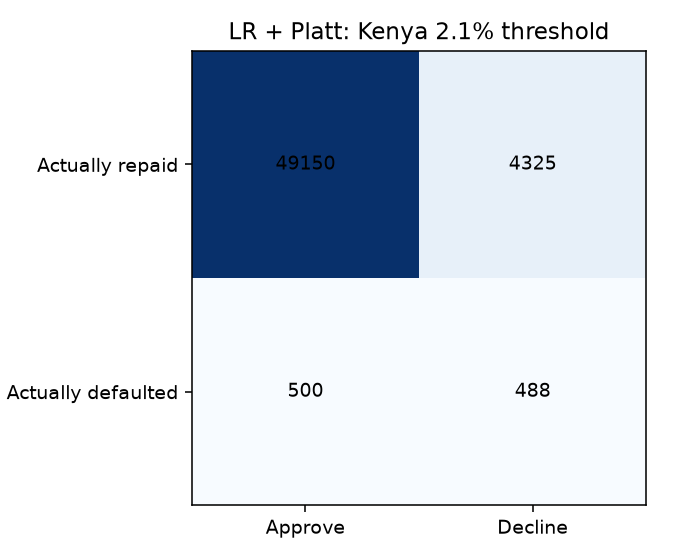

In [4]:
folds = pd.read_csv(TABLES / "07_model_fold_metrics.csv")
display(folds.query("scheme == 'time_block' and model == 'Logistic Regression'"))
display(Image(filename=str(FIGURES / "07_confusion_matrix.png")))


## 4. Reliability curve

Points should be near the diagonal when model probabilities reflect observed frequencies. Large changes in defaults over time can harm calibration.


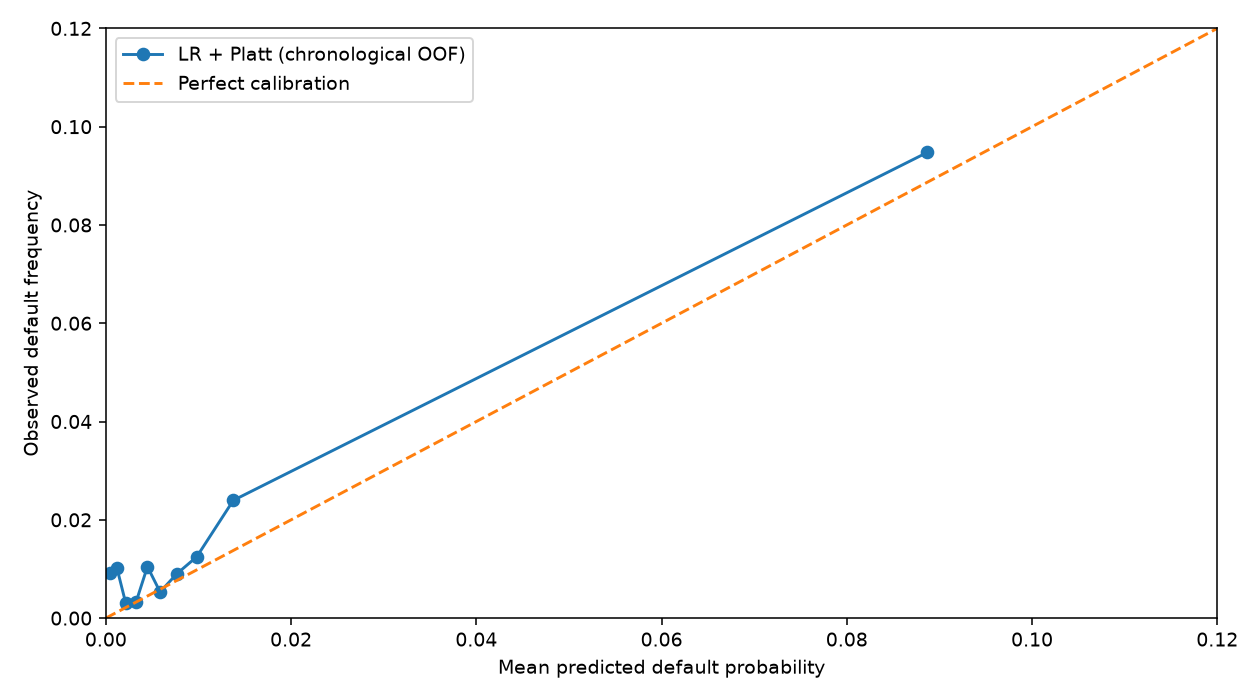

In [5]:
display(Image(filename=str(FIGURES / "07_reliability_curve.png")))


## 5. Cost and approval across periods

These results are evaluated on labelled Kenyan loans. A row described as “Kenyan loans at Ghana 3.2%” is **not** observed Ghanaian model performance. Do not approve a commercial policy from this simulation.


In [6]:
periods = pd.read_csv(TABLES / "07_approval_by_period.csv")
display(periods.sort_values(["scenario","period","fold"]))


,period,fold,scenario,n,defaults,approval_rate,approved_default_rate,cost_per_loan
0,2022Q3,0,Kenya 2.1%,13850,175,0.989603,0.011747,55.574007
2,2022Q3,1,Kenya 2.1%,13250,151,0.978943,0.009637,46.249057
4,2022Q3,2,Kenya 2.1%,556,6,0.980216,0.009174,44.064748
6,2022Q4,2,Kenya 2.1%,13220,123,0.969138,0.007025,34.833585
8,2022Q4,3,Kenya 2.1%,9564,132,0.908616,0.007250,39.376830
10,2023Q1,3,Kenya 2.1%,346,39,0.132948,0.043478,103.179191
12,2023Q2,3,Kenya 2.1%,182,27,0.093407,0.117647,128.571429
14,2023Q3,3,Kenya 2.1%,372,50,0.077957,0.068966,104.569892
16,2023Q4,3,Kenya 2.1%,339,27,0.053097,0.000000,86.725664
18,2024Q1,3,Kenya 2.1%,97,14,0.020619,0.000000,83.505155


### Which cut-off? (added by Joseph, 28 Oct)

Each future-loan block is scored with six policies: approve everyone, the 2.1% cost cut-off, the 9.6% repeat-business cut-off, and approving the lowest-risk 70% / 80% / 90%. The approval targets use only the block's own scores (no labels), so NkwaPay could apply them on the day. Cost is per loan in KES, with Liza's main costs (4,700 / 100) and repeat-business costs (4,700 / 500).

In [7]:
ops = pd.read_csv(TABLES / "07_operating_points.csv")
display(ops[["period","default_rate","policy","approval_rate","approved_default_rate","cost_main_KES","cost_repeat_KES"]].round(3))
w = ops.assign(main=ops.cost_main_KES*ops.n, repeat=ops.cost_repeat_KES*ops.n, approved=ops.approval_rate*ops.n).groupby("policy")[["main","repeat","approved","n"]].sum()
display(w[["main","repeat","approved"]].div(w.n, axis=0).round(3).sort_values("main"))

,period,default_rate,policy,approval_rate,approved_default_rate,cost_main_KES,cost_repeat_KES
0,02 Aug 2022 – 02 Sep 2022,0.013,Approve everyone (no model),1.000,0.013,59.386,59.386
1,02 Aug 2022 – 02 Sep 2022,0.013,Cost cut-off 2.1%,0.990,0.012,55.574,59.329
2,02 Aug 2022 – 02 Sep 2022,0.013,Repeat-business cut-off 9.6%,0.997,0.012,56.563,57.487
3,02 Aug 2022 – 02 Sep 2022,0.013,Approve 70% (lowest risk),0.700,0.011,65.126,183.105
4,02 Aug 2022 – 02 Sep 2022,0.013,Approve 80% (lowest risk),0.800,0.010,56.859,134.982
5,02 Aug 2022 – 02 Sep 2022,0.013,Approve 90% (lowest risk),0.900,0.009,48.245,86.484
6,03 Sep 2022 – 29 Sep 2022,0.011,Approve everyone (no model),1.000,0.011,53.562,53.562
7,03 Sep 2022 – 29 Sep 2022,0.011,Cost cut-off 2.1%,0.979,0.010,46.249,53.887
8,03 Sep 2022 – 29 Sep 2022,0.011,Repeat-business cut-off 9.6%,0.999,0.011,50.740,50.800
9,03 Sep 2022 – 29 Sep 2022,0.011,Approve 70% (lowest risk),0.700,0.005,45.162,161.962


,main,repeat,approved
policy,,,
Cost cut-off 2.1%,51.090,82.854,0.912
Approve 70% (lowest risk),54.450,169.383,0.700
Approve 80% (lowest risk),57.140,133.125,0.800
Approve 90% (lowest risk),62.143,99.115,0.901
Repeat-business cut-off 9.6%,69.016,76.522,0.977
Approve everyone (no model),85.262,85.262,1.000


## 6. Threshold sensitivity

The 2.1% cutoff comes from the cost matrix, not from tuning on test outcomes. The threshold sweep below is descriptive; choosing a new optimum from these evaluated rows would produce optimistic performance estimates.


In [8]:
sweep=pd.read_csv(TABLES / "07_lr_threshold_sweep.csv")
display(sweep.loc[(sweep.threshold-.021).abs().sort_values().index[:1]])
display(sweep.sort_values("f1",ascending=False).head(5))


,threshold,n,defaults,pr_auc,roc_auc,brier,log_loss,precision,recall,f1,tn,fp,fn,tp,approval_rate,approved_default_rate,cost_per_loan_KES
37,0.021,54463,988,0.109038,0.76755,0.018082,0.090756,0.101392,0.493927,0.168247,49150,4325,500,488,0.911628,0.01007,51.089731


,threshold,n,defaults,pr_auc,roc_auc,brier,log_loss,precision,recall,f1,tn,fp,fn,tp,approval_rate,approved_default_rate,cost_per_loan_KES
56,0.086819,54463,988,0.109038,0.76755,0.018082,0.090756,0.165430,0.225709,0.190925,52350,1125,765,223,0.975249,0.014403,68.082919
58,0.096000,54463,988,0.109038,0.76755,0.018082,0.090756,0.170455,0.212551,0.189189,52453,1022,778,210,0.977379,0.014616,69.015662
60,0.111254,54463,988,0.109038,0.76755,0.018082,0.090756,0.178218,0.200405,0.188661,52562,913,790,198,0.979601,0.014807,69.851092
59,0.102428,54463,988,0.109038,0.76755,0.018082,0.090756,0.172619,0.205466,0.187616,52502,973,785,203,0.978407,0.014732,69.529773
57,0.094301,54463,988,0.109038,0.76755,0.018082,0.090756,0.167464,0.212551,0.187333,52431,1044,778,210,0.976975,0.014622,69.056056


## 7. Paired bootstrap and ±0.0263 noise floor

Compare Logistic Regression and Random Forest on the same chronological loans with customer-cluster resampling. A point estimate above the noise floor is not proof that the full confidence interval exceeds it.


In [9]:
print((TABLES / "07_noise_floor_comparison.md").read_text(encoding="utf-8"))


LR minus RF pooled chronological PR-AUC = +0.01536. Paired customer-bootstrap 95% interval [+0.00089, +0.03255], 300 valid replicates. Noise floor ±0.0263. Point estimate exceeds noise floor: False. Interval wholly above positive floor: False. Per time block (each scored on its own), LR minus RF = +0.0134, +0.0772, +0.0621, +0.0043; mean +0.0393, LR ahead in 4/4 blocks. The bootstrap describes uncertainty for this validation procedure, not Ghana performance.



## 8. Decision and limitations

**Chosen integration candidate: standard Logistic Regression + Platt calibration.** It is interpretable and supported by prior bootstrap evidence. Require chronological performance and calibration review before approving a lending policy. Ghana is unlabeled; fairness and transfer results must not be invented.

Local individual predictions stay in ignored `data/experiments/` and should **never** be committed to GitHub. Aggregate tables and figures belong in `learnings/`.
